# BATMAN tutorial — modelling an exoplanet transit

**Computational Astrophysics 2026/2027 · Assignment 1 companion**

This notebook guides you through the same steps as the galaxy tutorial: **choose an astrophysical target, configure a model, calculate a curve, visualise the result, and save a figure**. Here we use [`batman`](https://lkreidberg.github.io/batman/docs/html/quickstart.html) to simulate a *planet crossing the disc of its host star*.

For **Task F**, choose **your own transiting exoplanet**, look up its published properties, adapt the example values below, and save the figure using the required filename. The numbers provided here are **teaching examples** and are not a substitute for a documented parameter set. This notebook generates a **model light curve**, not observed photometric measurements.

## 1 · Imports and configuration

In the conda environment prepared for **Task E**, install the numerical/plotting packages and BATMAN (`conda install numpy matplotlib` and `python -m pip install batman-package`, or use your preferred conda channels).

- `PLANET_NAME` identifies the object in your plot and exported filename.
- All orbital times must use the **same unit** (days in this notebook).
- The **planet-to-star radius ratio** $R_p/R_*$ and **scaled semi-major axis** $a/R_*$ are **dimensionless**. Do not put an unconverted radius in Earth/Jupiter radii directly into `params.rp`.

Useful catalogues: [The Extrasolar Planets Encyclopaedia](https://exoplanet.eu/catalog/) and the [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu/).

In [2]:
!pip install batman-package

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for batman-package: filename=batman_package-2.5.2-cp314-cp314-linux_x86_64.whl size=76561 sha256=ad7a445904aa12083738dcfb37b9f07c51f866a63e26b31b47545895a3054fb0
  Stored in directory: /root/.cache/pip/wheels/22/fb/f6/0ef58c75519a5d4f3f6f99b6e597892efaebb8b29d67ca15fc
Successfully built batman-package


In [3]:
from pathlib import Path
import re

import batman  # from the pip/conda distribution named "batman-package"
import matplotlib.pyplot as plt
import numpy as np

# Change this when you choose the transiting planet for Task F.
PLANET_NAME = "WASP-39 b"  # illustrative starting point; verify current parameters

print("NumPy version:", np.__version__)
print("Target:", PLANET_NAME)

NumPy version: 2.4.6
Target: WASP-39 b


## 2 · Stellar limb darkening

The stellar disc is generally brighter at its centre than near its edge. We use the **quadratic limb-darkening law**

$$I(\mu)/I(1) = 1 - u_1(1-\mu) - u_2(1-\mu)^2.$$

The coefficients $u_1$ and $u_2$ depend on the **host star** and the **photometric passband**. The default values below are **illustrative only**, so they let everyone run the tutorial without the local ExoCTK file used in the original notebook.

To obtain suitable coefficients, try the [ExoCTK limb-darkening calculator](https://exoctk.stsci.edu/limb_darkening). You may enter published coefficients manually, or provide a local tabular export and **check which columns correspond to your selected law and bandpass** before using it.

In [4]:
# Simple working defaults — NOT observational coefficients for the target.
u1, u2 = 0.099, 0.13

# OPTIONAL: use the legacy ExoCTK export format from the earlier tutorial.
# This is a relative path; no files on the teacher's computer are required.
# Confirm that columns 8 and 10 (zero-based) really store the intended u1/u2.
LD_TABLE = Path("ExoCTK_results.txt")
if LD_TABLE.is_file():
    table = np.atleast_2d(np.genfromtxt(LD_TABLE, skip_header=2))
    if table.shape[1] <= 10:
        raise ValueError("ExoCTK file has too few columns: check its format")
    valid = table[:, [8, 10]]
    valid = valid[np.isfinite(valid).all(axis=1)]
    if len(valid) == 0:
        raise ValueError("ExoCTK table contains no valid coefficient pairs")
    u1, u2 = map(float, valid.mean(axis=0))
    print("Limb darkening: average of selected columns in", LD_TABLE)
else:
    print("Limb darkening: illustrative coefficients (no local ExoCTK table)")

print(f"Quadratic limb-darkening coefficients: u1={u1:.3f}, u2={u2:.3f}")

Limb darkening: illustrative coefficients (no local ExoCTK table)
Quadratic limb-darkening coefficients: u1=0.099, u2=0.130


## 3 · Set the physical parameters

`batman.TransitParams()` stores the geometry of a single planet's transit. Below are the important variables to look up for **your own target**:

| Parameter | Meaning | Units |
|:--|:--|:--|
| `t0` | Epoch of transit centre; set to 0 if plotting relative time | days |
| `per` | Orbital period | days |
| `rp` | Planet radius divided by stellar radius | $R_p/R_*$ |
| `a` | Semi-major axis divided by stellar radius | $a/R_*$ |
| `inc` | Orbital inclination | degrees |
| `ecc` | Eccentricity | dimensionless |
| `w` | Argument of periastron | degrees |
| `u`, `limb_dark` | Limb-darkening law and coefficients | dimensionless |

For an **eccentric orbit**, the appropriate `w` value matters. For a **circular orbit**, the BATMAN quickstart uses `w = 90` degrees by convention. The values below reproduce the *character* of the earlier notebook; replace them with a consistent, referenced parameter set for the assignment.

In [5]:
params = batman.TransitParams()
params.t0 = 0.0          # time of central transit; 0 means relative time here [days]
params.per = 4.0552941 # orbital period [days] — example only
params.rp = 0.13973482428115 # Rp / Rstar (dimensionless) — example only
params.a = 11.0560685836 # a / Rstar (dimensionless) — example only
params.inc = 87.32       # orbital inclination [degrees]
params.ecc = 0.0         # eccentricity (0 = circular)
params.w = 90.0          # argument of periastron [degrees]; BATMAN convention if ecc=0
params.limb_dark = "quadratic"
params.u = [u1, u2]     # quadratic coefficients for the chosen stellar passband

# Quick, approximate transit depth for an un-darkened stellar disc.
# The exact BATMAN curve also depends on limb darkening and geometry.
print(f"Approx. transit depth: {(params.rp**2)*100:.2f}%")

Approx. transit depth: 1.95%


## 4 · Choose the observation times

`np.linspace(start, stop, number)` creates evenly spaced times. Because we set `t0 = 0`, the x-axis represents **time relative to transit centre** rather than an absolute Julian date.

A window that is too narrow can miss ingress or egress. For a different planet, adjust the time span to include **out-of-transit points on both sides**.

In [9]:
# 1,000 simulated time samples over 0.15 days (about 3.6 hours).
t = np.linspace(-0.08, 0.08, 1000)
print(f"Time coverage: {t[0]:.3f} to {t[-1]:.3f} days, {len(t)} samples")

Time coverage: -0.080 to 0.080 days, 1000 samples


## 5 · Compute the model light curve

A `TransitModel` object connects the orbital parameters to the observation times. `light_curve()` returns **relative stellar flux**: values near 1 outside transit and a dip below 1 during transit.

This is the core calculation you should transfer into your reusable `src/daneel/detection/transit.py` implementation for Task F. A smaller `rp` generally produces a shallower transit; changing `inc` changes the impact parameter and transit duration.

In [10]:
model = batman.TransitModel(params, t)  # initialise the transit model
flux = model.light_curve(params)           # calculate the normalised flux

assert flux.shape == t.shape
assert np.all(np.isfinite(flux)), "The light curve contains non-finite values"
print(f"Minimum model flux: {flux.min():.6f}")
print(f"Maximum model flux: {flux.max():.6f}")

Minimum model flux: 0.979719
Maximum model flux: 1.000000


## 6 · Plot and save — the figure required by Task F

Matplotlib creates the plot. The `.png` must be produced by **your own model** with your chosen exoplanet parameters, not simply copied from this notebook.

The output name is generated automatically in the format required by the assignment, for example `HD_189733_b_assignment1_taskF.png`. If you prefer, change `output_file` manually to match your selected planet's name exactly. Verify that the saved file exists before committing it.

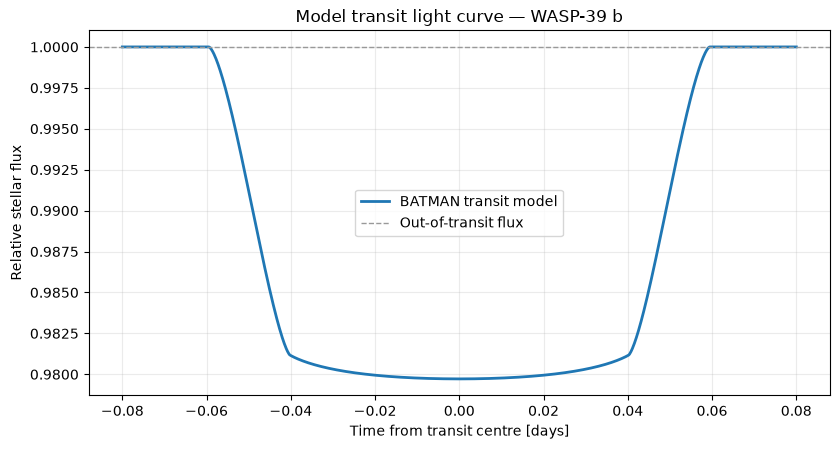

Saved: /ca26/comp_astro_26/WASP_39_b_assignment1_taskF.png


In [11]:
# Replace punctuation and spaces in the planet name to make a safe filename.
planet_slug = re.sub(r"[^A-Za-z0-9]+", "_", PLANET_NAME).strip("_")
output_file = Path(f"{planet_slug}_assignment1_taskF.png")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(t, flux, lw=2, label="BATMAN transit model")
ax.axhline(1.0, color="0.6", lw=1, ls="--", label="Out-of-transit flux")
ax.set(xlabel="Time from transit centre [days]", ylabel="Relative stellar flux",
       title=f"Model transit light curve — {PLANET_NAME}")
ax.grid(alpha=0.25)
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(output_file, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", output_file.resolve())
assert output_file.is_file()

## 7 · A short experiment (optional)

Try increasing or decreasing `params.rp` and then re-running Sections 5 and 6. How does the transit depth change? Try a different inclination: does the transit become shorter, grazing, or disappear?

**Important:** do not mix planetary parameters from unrelated literature solutions without checking consistency (e.g. orbital period, epoch, inclination, and scaled semi-major axis). Note the source of your selected planet's parameters in your report or a code comment.

## Moving from this tutorial to Assignment 1

**Task E:** document your conda environment and installed packages in `assignment1_taskE.txt`.

**Task F:** implement a reusable calculation in `src/daneel/detection/transit.py` and commit both the Python code and the planet-named PNG file. For your submission, replace the illustrative parameters and limb-darkening coefficients with justified values for your selected system.

**Challenge G:** connect the method to the `daneel -i ... -t` command-line flag and document it in `README.md`.

**Challenge H:** read planetary parameters from a YAML file with the existing `daneel.parameters.Parameters` class; run the installed command from a directory **outside** your Git repository.

### References

- [BATMAN quickstart](https://lkreidberg.github.io/batman/docs/html/quickstart.html) and [full tutorial](https://lkreidberg.github.io/batman/docs/html/tutorial.html)
- Kreidberg, L. (2015), *batman: BAsic Transit Model cAlculatioN in Python*, PASP **127**, 1161–1165. [DOI: 10.1086/683602](https://doi.org/10.1086/683602)
- [The Extrasolar Planets Encyclopaedia](https://exoplanet.eu/catalog/) and [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu/)
- [ExoCTK limb-darkening calculator](https://exoctk.stsci.edu/limb_darkening)